# TD 3: Replay of the neural activity during sleep after a task

Understanding how memories are stored and consolidated in the brain is one of the fundamental goals
of neuroscience. It is known that short term memories are stored in the brain area called the hippocampus
while long term memories are stored in the brain area called the prefrontal cortex. It is important to better
understand how memories are transmitted from the hippocampus to the cortex and what is the role of sleep
for memory consolidation and learning processes. To such aim, multi-electrode recording of a few dozens of
neurons in the prefrontal cortex of alive rats have been performed by F. Battaglia’s group [[1](https://hal.science/hal-00551868), [2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)]. A single
recording session, in which the same neurons are recorded, is divided into three epochs: 
- a $task$ epoch in
which the rat has to learn, by trials and errors, what is the rewarded arm in a Y-shaped maze (there are
four possible rules which are changed by the operator as soon as the rat learns them: go to the left arm, go
to the right arm, go where a light is on, go where a light is off);
- a $pre-task$ sleep epoch;
- a $post-task$ sleep epoch.

**The goal of this tutorial is to analyze the recording data using principal component
analysis and tools from random matrix theory**, in order to detect similarities between the neuronal activity
during the $task$ and during the $post-task$ sleep epochs, which where not present in the $pre-task$ sleep epoch.
OBS: The paper uses many sessions to draw their results. We will only use the data of one session.

![PrePost.png](PrePost.png)
**Caption:** Reactivation strength (black and white traces; right axes) of the signal component during sleep pre (left) and
post (right) epochs superimposed on the spectrogram (left axes). White traces indicate slow-wave sleep (SWS) periods and black traces indicate non-SWS. The
spectrogram shows periods of elevated slow/delta and spindle oscillations
often coinciding with SWS. Reactivation strengths show high peaks during
post epoch SWS, usually concomitant with periods of strong oscillations.

# Data:
The spiking activity of a population of $L = 37$ prefrontal cortex neurons during the


- **$pre-task$ sleep (Dati_181014_sleep1.txt)**
- **$task$ (Dati_181014_maze.txt)**
- **$post-task$ sleep (Dati_181014_sleep2.txt)**

epochs can be downloaded from the course webpage, see Tutorial 3 repository. Each file contains a two-
column array $\lbrace t_i , i \rbrace$, where $t_i$ is a spiking time of neuron $i$ (**times are in units of 0.1 ms**), ranging between
$T_{min}$ and $T_{max}$ , and $i$ is the neuron index. Data are taken from Ref. [[1](https://hal.science/hal-00551868)].

# Problem

During a recording session, $L$ neurons, labeled by $i=1,\ldots,L$, are recorded for a total time $T$. We discretize their spike trains into time bins of width $\Delta t=100\,\mathrm{ms}$.

Assuming $T$ is an integer multiple of $\Delta t$, the number of bins is $M=T/\Delta t$. We denote the center of bin $b$ by $t_b$, where $b=1,\ldots,M$.

The activity of neuron $i$ in the interval $[t_b-\Delta t/2,\;t_b+\Delta t/2)$ is represented by its spike count $s_i(t_b)\in\{0,1,2,\ldots\}$.

## Standardized activity

For each neuron $i$, define its mean spike count and sample variance across time bins:

$$
p_i=\frac{1}{M}\sum_{b=1}^{M}s_i(t_b),
$$

$$
\sigma_i^2=\frac{1}{M-1}\sum_{b=1}^{M}\left(s_i(t_b)-p_i\right)^2.
$$

Here, $p_i$ is a mean count per bin, not a probability.

For neurons with $\sigma_i>0$, define the standardized activity:

$$
y_{b,i}=\frac{s_i(t_b)-p_i}{\sigma_i}.
$$

These values form an $M\times L$ matrix $Y$:

- Each row represents the standardized activity of all $L$ neurons in one time bin: one observation in $L$-dimensional neuron space.
- Each column represents the standardized activity of one neuron across all $M$ time bins.

Each column has zero mean and unit sample variance. Neurons with zero variance must be excluded before standardization; $L$ then denotes the number of retained neurons.

## Pearson correlation matrix

The $L\times L$ Pearson correlation matrix is

$$
C=\frac{1}{M-1}Y^\top Y,
$$

or, entry by entry,

$$
C_{i,j}=\frac{1}{M-1}\sum_{b=1}^{M}y_{b,i}y_{b,j}.
$$

The normalization $1/(M-1)$ matches the sample variance used above and gives $C_{i,i}=1$.

A positive value of $C_{i,j}$ means that neurons $i$ and $j$ tend to fluctuate together relative to their respective means. A negative value means that they tend to fluctuate in opposite directions.

## Principal component analysis

Since $C$ is symmetric, it can be diagonalized:

$$
C\boldsymbol{v}^{(k)}=\lambda_k\boldsymbol{v}^{(k)},
$$

where the eigenvectors are chosen to have unit norm.

Each eigenvector $\boldsymbol{v}^{(k)}$ defines a pattern of weights across neurons. The corresponding principal component score in bin $b$ is

$$
z_{b,k}=\sum_{i=1}^{L}y_{b,i}v_i^{(k)}.
$$

Its sample variance is the corresponding eigenvalue:

$$
\frac{1}{M-1}\sum_{b=1}^{M}z_{b,k}^{\,2}=\lambda_k.
$$

Large eigenvalues therefore identify directions with strong population fluctuations. These directions can reveal candidate cell assemblies.

## Random-matrix noise baseline

Finite sampling produces nonzero sample correlations even when the underlying variables are independent.

Under an idealized null model of independent, standardized observations with suitable finite moments, the eigenvalue distribution approaches the Marchenko-Pastur law as $L$ and $M$ become large with a fixed ratio

$$
r=\frac{L}{M}<1.
$$

Its density is

$$
\rho(\lambda)=
\frac{\sqrt{(\lambda_+-\lambda)(\lambda-\lambda_-)}}{2\pi r\lambda},
\qquad \lambda\in[\lambda_-,\lambda_+],
$$

and zero outside this interval, where

$$
\lambda_\pm=(1\pm\sqrt{r})^2.
$$

This is an asymptotic approximation; centering and the use of $M-1$ introduce small finite-sample corrections.

To identify candidate high-variance signal components, we select eigenvalues above the upper noise edge:

$$
\lambda_k>\lambda_+.
$$

Such outliers indicate departures from the idealized noise model, rather than proving biological significance. Temporal dependence and other departures from the model can affect the spectrum, so shuffled-data controls provide an additional check.

In [151]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
import numpy.matlib
import pandas as pd
from IPython.display import display, Math

# Set global font sizes for labels and ticks
# plt.rcParams['axes.labelsize'] = 20    # axis labels (xlabel, ylabel)
# plt.rcParams['xtick.labelsize'] = 16   # x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 16   # y-axis tick labels

L = 37
DT_TICKS = 1000            # 100 ms / (0.1 ms per timestamp unit)
DT_SECONDS = 0.1

### Question 1 - Read and visualize the recordings
Read the data and produce the raster plot for the $L$ neurons and the first $10$ seconds of the activity. Note
that in reading the data, you should find $T_{min}$ and $T_{max}$ for each epoch.

PRE: Tmin=0.005, Tmax=1769.7261 seconds
TASK: Tmin=1986.0105, Tmax=3394.5225 seconds
POST: Tmin=3544.5266, Tmax=5187.3567 seconds


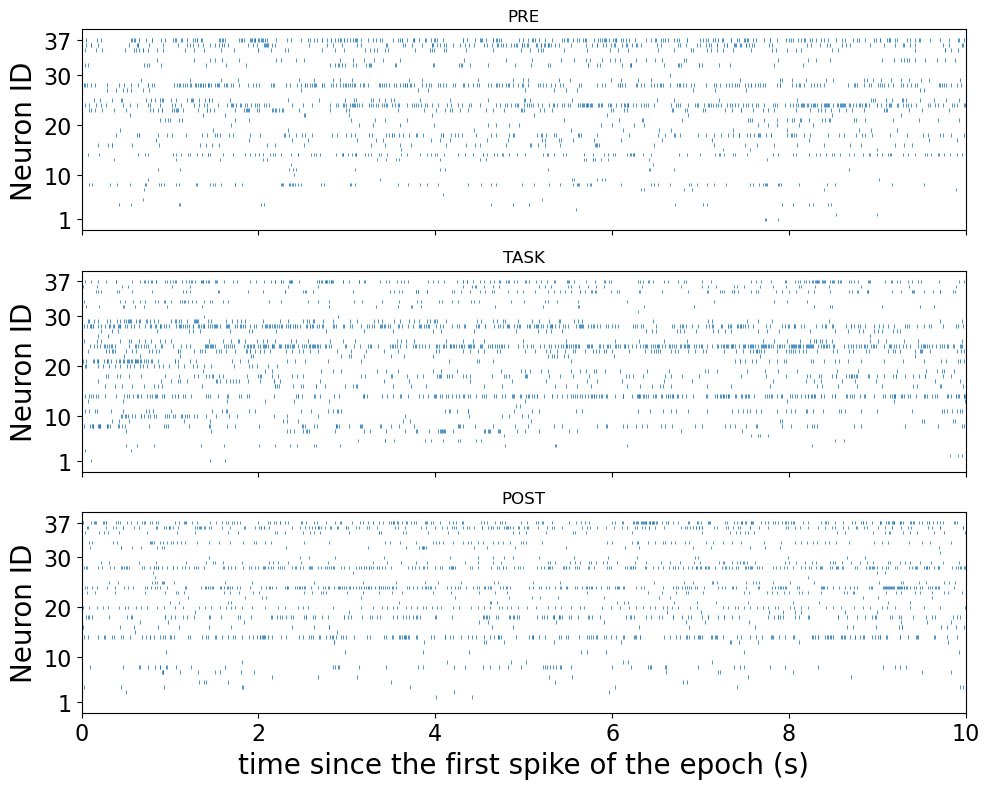

In [152]:
# Read and visualize all three epochs
datapaths = ('Data/Dati_181014_sleep1.txt','Data/Dati_181014_maze.txt','Data/Dati_181014_sleep2.txt')
labels = ('PRE', 'TASK', 'POST')

fig, axes = plt.subplots(3,1,figsize=(10,8), sharex=True,sharey=True)


for ax, path, label in zip(axes,datapaths,labels):
    data = np.loadtxt(path)
    times, neurons_ids = data[:, 0], data[:, 1]
    t_min, t_max = times.min(), times.max()
    t_seconds = (times - t_min) / 10_000
    print(f"{label}: Tmin={t_min/10_000}, Tmax={t_max/10_000} seconds")
    
    first_10_s = t_seconds < 10.
    ax.vlines(t_seconds[first_10_s], neurons_ids[first_10_s] - 0.35, neurons_ids[first_10_s] + 0.35, lw=.55)
    ax.set_title(label)
    ax.set_ylabel("Neuron ID")
    ax.set_xlim(0, 10)
    ax.set_yticks([1, 10, 20, 30, L])
    
axes[-1].set_xlabel("time since the first spike of the epoch (s)")
fig.tight_layout()
plt.show()

### Question 2 - bin spikes and count distributions
In this question, we consider only the $task$ data.

##### Question 2 (i): 
Write a function that takes the data (which are binary) and compute the $M\times L$ matrix $(s_i(t_b))_{b,i}$ with the discretization time bin $\Delta t=100 ms$ (we recall that data are obtained every $0.1ms$). 
Compare the observed ocunt distribution with Poisson distribution (available in `scipy.stats.poisson`, submodule `pmf`) of the same mean, both after pooling all neurons and for one individual neuron. Use a logarithmic vertical axis so that the tails are visible.

In [153]:
def bin_spikes(data, L=37, dt=1_000):
    times, neuron_ids = data[:, 0], data[:, 1].astype(int)
    t_min = times.min()
    
    bin_ids = np.floor((times - t_min) / dt).astype(int) # find time bin (row) for each spike
    M = bin_ids.max() + 1
    counts = np.zeros((M, L), dtype=int)
    
    for b, neuron_id in zip(bin_ids, neuron_ids):
        counts[b, neuron_id-1] += 1
    
    return counts
    
task_data = np.loadtxt(datapaths[1])
S_task = bin_spikes(task_data)


A simple baseline models each neuron's spike train as a **homogeneous Poisson process** with constant firing rate $\nu_i$. Counts in disjoint time bins are then independent, and the count in a bin of width $\Delta t$ follows

$$
s_i(t_b)\sim\operatorname{Poisson}(\nu_i\Delta t).
$$

We estimate the expected count $\nu_i\Delta t$ using the empirical mean $p_i$ and compare the observed count distribution with $\operatorname{Poisson}(p_i)$.

Departures can reflect bursting, refractory effects, or changing firing rates. A matching histogram alone does not establish temporal independence. Also, pooling neurons with different rates produces a mixture of Poisson distributions, which generally differs from a single Poisson distribution with the pooled mean.

/var/folders/hr/wt83vx857tb5stw6bpqw6ss00000gn/T/ipykernel_2199/2760291342.py:33: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


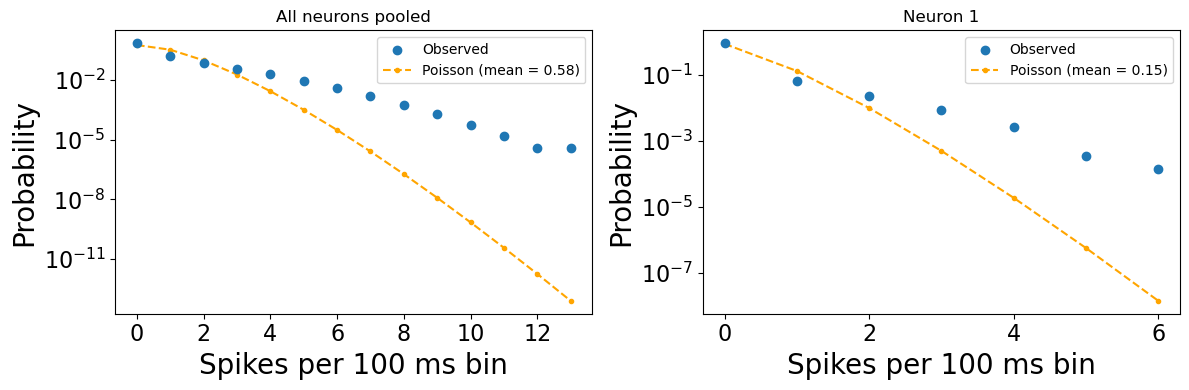

In [154]:
from scipy.stats import poisson

neuron_id = 1

samples = (
    S_task.ravel(),             # Pool neuron-bin counts into one sample.
    S_task[:, neuron_id - 1]    # Counts for one neuron across time.
)
titles = ("All neurons pooled", f"Neuron {neuron_id}")

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4),
    constrained_layout=True
)

for ax, counts, title in zip(axes, samples, titles):
    mean = counts.mean()
    k = np.arange(counts.max() + 1)
    
    empirical = np.bincount(counts) / len(counts)
    predicted = poisson.pmf(k, mean)
    
    positive = empirical > 0
    ax.scatter(k[positive], empirical[positive], label="Observed", zorder=3)
    ax.plot(k, predicted, "o--", markersize=3, label=f"Poisson (mean = {mean:.2f})", color="orange")
    ax.set_yscale("log")
    ax.set_xlabel("Spikes per 100 ms bin")
    ax.set_ylabel("Probability")
    ax.set_title(title)
    ax.set_xticks(np.arange(0, counts.max()+1, 2))
    ax.legend()

fig.tight_layout()
plt.show()

##### Question 2 (ii):
Compute the Pearson correlation matrix of the $task$ activity and diagonalize it. Compare the spectrum
of eigenvalues of $C$ task to the Marchenko-Pastur distribution to extract the signal components associated to
large eigenvalues. How many signal components with $\lambda > \lambda_+$ are present? Use `np.linalg.eigh`.

In [155]:
M = S_task.shape[0]

# standarize each neuron across time bins
p = S_task.mean(axis=0)
sigma = S_task.std(axis=0, ddof=1)

Y = (S_task - p) / sigma

C = Y.T @ Y / (M - 1)
evals_C, evecs_C = np.linalg.eigh(C)

MP interval: [0.9001, 1.1051]
Components above the upper noise edge: 6


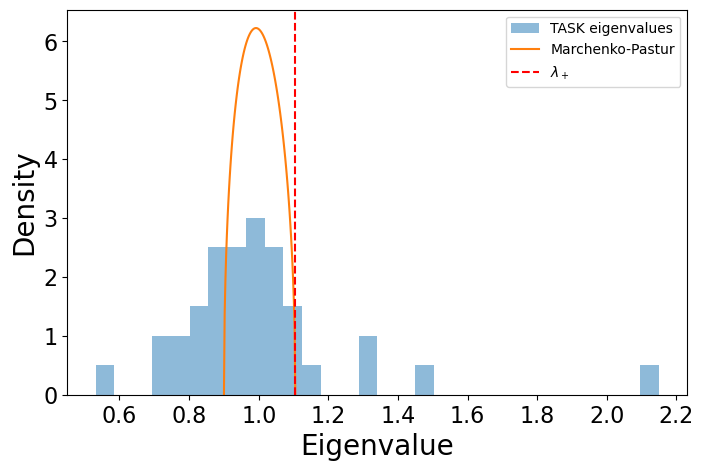

In [156]:
r = L / M
lp, lm = (1 + np.sqrt(r))**2, (1 - np.sqrt(r))**2

def MP(x):
    return np.sqrt(np.maximum((lp - x) * (x - lm), 0)) / (
        2 * np.pi * r * x
    )

xs = np.linspace(lm, lp, 100)

n_signal = np.sum(evals_C > lp)
print(f"MP interval: [{lm:.4f}, {lp:.4f}]")
print(f"Components above the upper noise edge: {n_signal}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(evals_C, bins=30, density=True, alpha=0.5,
        label="TASK eigenvalues")
ax.plot(xs, MP(xs), label="Marchenko-Pastur")
ax.axvline(lp, color="red", linestyle="--", label=r"$\lambda_+$")
ax.set_xlabel("Eigenvalue")
ax.set_ylabel("Density")
ax.legend()
plt.show()

### Question 3 - Shuffling the data

Reshuffle the data, by randomly permuting the activity of the single neurons over the $M$ possible time
bins, in such a way that the correlations between neurons spiking together are lost, but the frequencies of
individual neurons are kept constant. Verify that the spectrum of the eigenvalues of the Pearson correlation
matrix of the shuffled data is well described by the Marchenko-Pastur distribution.

MP interval: [0.9001, 1.1051]
Components above the upper noise edge: 0


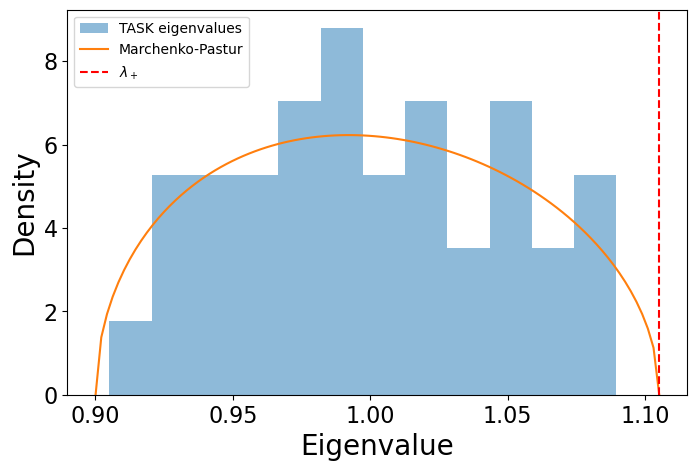

In [159]:
rng = np.random.default_rng(42)
S_shuffled = S_task.copy()

# shuffle each neuron's column independently
for i in range(S_shuffled.shape[1]):
    rng.shuffle(S_shuffled[:, i])

# standarize each neuron across time bins
p = S_shuffled.mean(axis=0)
sigma = S_shuffled.std(axis=0, ddof=1)

Y_shuffled = (S_shuffled - p) / sigma

C_shuffled = Y_shuffled.T @ Y_shuffled / (M - 1)
evals_C_shuffled, evecs_C_shuffled = np.linalg.eigh(C_shuffled)

r = L / M
lp, lm = (1 + np.sqrt(r))**2, (1 - np.sqrt(r))**2

def MP(x):
    return np.sqrt(np.maximum((lp - x) * (x - lm), 0)) / (
        2 * np.pi * r * x
    )

xs = np.linspace(lm, lp, 100)

n_signal = np.sum(evals_C_shuffled > lp)
print(f"MP interval: [{lm:.4f}, {lp:.4f}]")
print(f"Components above the upper noise edge: {n_signal}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(evals_C_shuffled, bins=12, density=True, alpha=0.5,
        label="TASK eigenvalues")
ax.plot(xs, MP(xs), label="Marchenko-Pastur")
ax.axvline(lp, color="red", linestyle="--", label=r"$\lambda_+$")
ax.set_xlabel("Eigenvalue")
ax.set_ylabel("Density")
ax.legend()
plt.show()

Shuffling each neuron's time bins **independently** destroys the original alignment of activity between neurons while preserving each neuron's spike-count distribution, mean, and variance. It also destroys temporal structure within each neuron.

Shuffling entire rows together would preserve all simultaneous activity patterns and leave the correlation matrix unchanged.

After independent shuffling, correlations fluctuate around zero, so the correlation matrix is approximately the identity:

$$
C_{\mathrm{shuffled}}\approx I.
$$

Finite sampling spreads its eigenvalues around 1. Under the idealized independent-data assumptions, this spread is described approximately by the Marchenko-Pastur law. The spike counts do not need to be Poisson distributed.

### Question 4 - Which neurons contribute to the top component?

Identify the neurons that contribute the most to the largest component of the task activity (largest entries in the eigenvector associated to the top eigenvalue). These neurons
identify a cell assembly of neurons coactivating during the task. **In `np.linalg.eigh`, the $i^{th}$ eigenvector corresponds to `eigvecs[:, -i]`**. 

Top five contributing neuron IDs: [20 21  1 26  9]


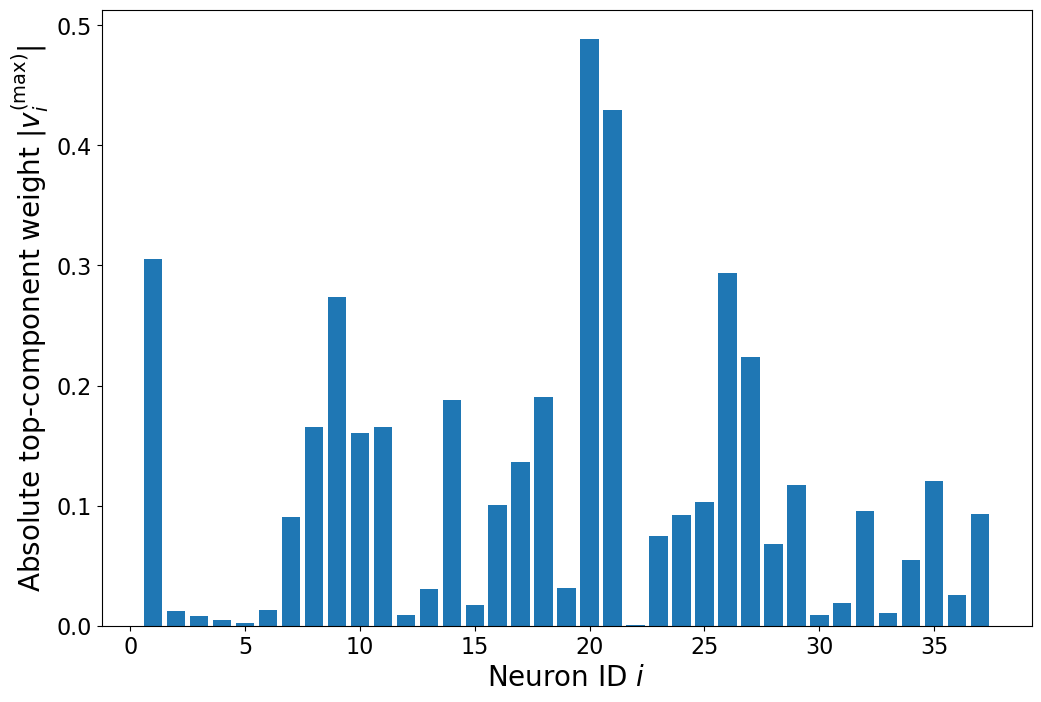

In [167]:
v_top = evecs_C[:, -1]
top5 = np.argsort(np.abs(v_top))[::-1][:5] + 1

print("Top five contributing neuron IDs:", top5)

fig, ax = plt.subplots(figsize=(12, 8))
ax.bar(np.arange(1, L + 1), np.abs(v_top))
ax.set_xlabel(r"Neuron ID $i$")
ax.set_ylabel(r"Absolute top-component weight $|v_i^{(\mathrm{max})}|$")
plt.show()

# Replay: 
We want to identify the similarity in the correlation structure between the sleep neuronal activity
(in the pre-task or post-task epochs) and the task activity. Following Peyrache et al. [[2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)], the task epoch is called
the template epoch, while the pre-task or post-task sleep epochs are called match epochs.
Each epoch's neurons are standardized within that epoch.
 An instantaneous
measure of similarity in the correlated activity is obtained by computing the scalar product, over all the
pairs of neurons, of the simultaneous co-activation of the pair during the match and the corresponding pair
correlation during the template,

$$  R^{match}(t_b)=\frac{1}{2} \sum_{i \neq j} y_{b,i}^{match} C_{i,j}^{template} y_{b,j}^{match}.  $$

Keeping only distinct neuron paris avoids letting one unusually active neuron dominate the match score (or replay).
Time averaging gives an equivalent correlation-matrix comparison

$$ \bar{R}^{match}= \frac{1}{M_{match}}\sum_b R^{match}(t_b)=\frac{1}{2} \sum_{i \neq j}  C_{i,j}^{template} C_{i,j}^{match} \approx \frac{1}{2}\text{Tr}\left[ (C^{match}-I)(C^{template}-I) \right],$$

where $\text{Tr}$ is the trace operation, $I$ is the identity matrix, and we used that, by definition, $C_{i,i} = (M −1)/M \approx 1$.

 Using the eigenvalue decomposition $C_{i,j}
= \sum_{k=1}^{L} \lambda_k v_i^{(k)} v_j^{(k)}$ in Eq. (5), one obtains the time-dependent
replay as a sum of replays associated to each principal component:

$$ R^{match}(t_b)= \sum_{k=1}^{L} \lambda_k R_k^{match}(t_b),$$

where 

$$ R_k^{match}(t_b)=\frac{1}{2}\left[ \left( \sum_{i=1}^L y_{b,i}^{match}v_i^{(k)} \right)^2 - \sum_{i=1}^L \left(y_{b,i}^{match}v_i^{(k)}\right)^2 \right] $$
 keeping in mind that $\boldsymbol{v}^{(k)}$ are the eigenvectors associated to the template epoch.

### Question 5 - Average TASK-pattern similarity in PRE and POST
Calculate the total replay of the pre-task sleep and post-task sleep epochs, with respect to the task epoch.

In [168]:
# Original TASK activity defines the template.
Y_task = (
    (S_task - S_task.mean(axis=0))
    / S_task.std(axis=0, ddof=1)
)
C_task = Y_task.T @ Y_task / (S_task.shape[0] - 1)

# Exclude self-interactions: keep only distinct neuron pairs.
C_template = C_task.copy()
np.fill_diagonal(C_template, 0)

replay = {}

for label, path in zip(("PRE", "POST"), (datapaths[0], datapaths[2])):
    S_match = bin_spikes(np.loadtxt(path))

    # Standardize within this sleep epoch.
    Y_match = (
        (S_match - S_match.mean(axis=0))
        / S_match.std(axis=0, ddof=1)
    )

    # One replay score per time bin:
    # R_b = (1/2) y_b.T @ C_template @ y_b
    replay[label] = 0.5 * np.sum(
        (Y_match @ C_template) * Y_match,
        axis=1
    )

    print(f"{label}: average replay = {replay[label].mean():.4f}")

PRE: average replay = 0.2907
POST: average replay = 0.5481


### Question 6 — When does matching activity occur?

Plot the replay as a function of time in the pre-task and post-task sleep epochs. Is
it constant in time? Compare with the results in Fig. 2 of Ref. [2].

![Fig2_2](Fig2_2.png)

### Question 7 - The top TASK component

Plot the first principal component of the replay $R^{match}_1(t_b)$ as a function of time in the pre-task and post-task sleep epochs. Is
it constant in time? Compare with the results of Question 6.

### Question 8 - Are strongly encoded TASK patterns stronger during POST?

For each TASK eigenvector, comput its variance during PRE and POST:
$$ \gamma_k^{match}= \boldsymbol{v}^{(k)T } C^{match} \boldsymbol{v}^{(k)} $$

Make a scatter plot of $\gamma_k$ versus $\lambda_k$ for the PRE and POST task epochs, for the components above the Question 2 MP edge.
Compare the average reactivation strength pre and post task as well, as shown Fig. 3 [2] (do a linear regression and plot the $y=x$ line). Conclude.

![Fig3_2](Fig3_2.png)

# References:

[[1](https://hal.science/hal-00551868)] Replay of rule-learning related neural patterns in the prefrontal cortex during sleep, A. Peyrache,
K. Benchenane, M. Khamassi, S. I. Wiener, F. P. Battaglia, Nature Neuroscience, DOI:10.1038/nn.2337
(2009).

[[2](https://pmc.ncbi.nlm.nih.gov/articles/PMC2940043/)] Principal component analysis of ensemble recordings reveals cell assemblies at high temporal resolution,
A. Peyrache , K. Benchenane, M. Khamassi, S. I. Wiener, F. P. Battaglia, Journal of Computational
Neuroscience, DOI:10.1007/s10827-009-0154-6 (2009).